# Lab: Relationships Between Categorical Features

Imagine James Cameron has hired you to develop two character profiles for a Titanic movie reboot: one “most likely to survive” and one “least likely to survive.” Support both profiles with passenger data and visualizations, then connect them to real people and their biographies.

These labels describe profiles suggested by observed group survival percentages in this dataset. They are not guaranteed individual outcomes, a validated prediction model, or proof that any feature caused survival.


## Learning goals

- Apply the six-step analysis workflow to categorical comparisons.
- Justify categories created from age and travel-companion counts.
- Distinguish raw counts from survival percentages within groups.
- Build clearly labeled figures and check their meaning.
- Support character profiles with evidence and identify matching passengers.
- Connect data records to cited historical biographies.


## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context? Do the original values support the coding and interpretation?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Use one six-step workflow for the complete character-profile investigation. All six feature comparisons belong together in Step 3: Evidence.


## Dataset and scope

Use the supplied `data/titanic_passengers.csv`, the 891-row training dataset from [Kaggle Titanic: Machine Learning from Disaster](https://www.kaggle.com/c/titanic/data). Each row represents a passenger in this file; it is not a complete passenger-and-crew list. Consult the source dictionary when interpreting the features.

Analyze only categorical comparisons with `Survived`. Use `Pclass` instead of `Fare`; do not analyze fare. Age is the exception: convert it to justified categories before comparing survival. Treat travel-companion counts as categories, combining sparse groups if appropriate. Use names and passenger IDs only to identify people.

| Feature | Meaning and role |
| --- | --- |
| `Survived` | Categorical outcome: 0 = did not survive, 1 = survived |
| `Pclass` | Ordered passenger class: 1, 2, or 3; categorical despite numeric storage |
| `Sex` | Recorded sex category |
| `Age` | Age in years; use only through your chosen age groups |
| `Parch` | Count of parents/children aboard; use as categories or collapse into groups |
| `SibSp` | Count of siblings/spouse aboard; use as categories or collapse into groups |
| `Embarked` | Embarkation port: C = Cherbourg, Q = Queenstown, S = Southampton |
| `Name`, `PassengerId` | Passenger identification for matching records to biographies |

The file also contains `Ticket`, `Fare`, and `Cabin`; do not use them as comparison features in this lab.


## Using AI tools responsibly

You may use AI for questions, debugging, or feedback. You remain responsible for understanding the code and checking claims against the output. Read the actual Encyclopedia Titanica biographies rather than using an uncited AI-generated fact. Disclose AI use in the final reflection.


## Step 1: Question

**Which categorical characteristics support a “most likely to survive” profile and a “least likely to survive” profile in this Titanic dataset?**

Consider age group, sex, passenger class, parents/children aboard, siblings/spouse aboard, and embarkation port together as parts of this one investigation.


**Before examining survival percentages, describe your predicted high-survival and low-survival profiles. What reasoning or prior knowledge supports your predictions?**

Your answer:  
    I predict that women and children traveling in first class were the most likely to survive, mainly because women and children were prioritized during evacuation and first-class passengers may have had better access to lifeboats.

I predict that adult men traveling in third class were the least likely to survive because of evacuation priorities and potentially limited access to lifeboats.

I also think having family aboard could influence survival, although I'm unsure whether it helped or hurt. The port of embarkation might also show differences based on passenger demographics and class.

These are my initial predictions based on historical knowledge. I'll compare all six categorical characteristics using the dataset to see whether the actual survival percentages support them.

## Step 2: Data


## Load and inspect the data

Use `titanic_df` as the DataFrame name. Keep the original columns so your category choices can be checked.


In [8]:
# Import pandas as pd and matplotlib.pyplot as plt.
import pandas as pd
import matplotlib.pyplot as plt

print("Both libraries loaded successfully!")

Both libraries loaded successfully!


In [13]:
# Read data/titanic_passengers.csv into titanic_df.
titanic_df = pd.read_csv("titanic_passengers.csv")

In [14]:
# Display the first five rows.
titanic_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [15]:
# Display .info().
titanic_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [16]:
# Display the missing-value count for each feature.
titanic_df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

**What does one row represent? Which feature is the target, and what do its codes mean?**

Your answer:  Each row represents one passenger aboard the Titanic. The target feature is `Survived`, which tells us whether that passenger survived the disaster. A value of `1` means the passenger survived, while `0` means they did not survive. We'll use this feature to compare survival rates across different passenger characteristics.

Complete this table from the inspection. Distinguish a feature's meaning from its Pandas storage type; numeric codes can represent categories.


| Feature | Data type (categorical/quantitative/identifier) | Data storage type | Missing values |
| --- | --- | --- | ---: |
| `PassengerId` | Identifier | int64 | 0 |
| `Name` | Identifier | object | 0 |
| `Survived` | Categorical | int64 | 0 |
| `Pclass` | Categorical | int64 | 0 |
| `Sex` | Categorical | object | 0 |
| `Age` | Quantitative | float64 | 177 |
| `Parch` | Quantitative | int64 | 0 |
| `SibSp` | Quantitative | int64 | 0 |
| `Embarked` | Categorical | object | 2 |


## Plan your age groups before comparing survival

Choose your own age categories. You might use children versus adults, split at 16, 18, or 20, or define several groups such as children, teens, young adults, and older adults. There is no single required cutoff. Give a reasoned argument based on the meaning of the groups and their usefulness, not just which split produces the strongest survival difference.

Write exact boundaries, including where an age exactly at a cutoff belongs. Cover all known ages without overlapping groups. Preserve unknown ages as missing or label them “Unknown”; do not accidentally classify them as adults. If you exclude unknown ages from this comparison, state that denominator choice. Do not guess an age from whether someone survived.



| Age-group label | Exact rule (including boundary values) | Reason for this choice |
| --- | --- | --- |
| Children | Age < 13 | Identifies younger passengers who may have received evacuation priority. |
| Teenagers | 13 <= Age < 18 | Separates adolescents from younger children and adults. |
| Adults | 18 <= Age < 60 | Represents the main adult passenger population. |
| Older Adults | Age >= 60 | Allows comparison of older passengers with other age groups. |
| Unknown | Age is missing (NaN) | Preserves passengers whose ages were not recorded without guessing. |

Add rows if needed.


**Why are your age groups reasonable? How will you handle unknown ages, and why?**

Your answer:  I separated passengers into children (under 13), teenagers (13–17), adults (18–59), and older adults (60 and above). These categories allow me to compare different stages of life and investigate whether age influenced survival.

I will keep passengers with missing ages in a separate "Unknown" category rather than guessing their ages or excluding them. This preserves the available records and avoids introducing assumptions that could affect the results.

Create `age_group` using `.loc` or `pd.cut`. If using `.loc`, initialize the column to an explicit “Unknown” label and assign labels only where ages satisfy your rules. If using `pd.cut`, choose its interval boundaries carefully and document whether intervals include their right or left endpoint. Count the observations in each category, including unknowns.


In [17]:
# Create age_group and display its category counts, including unknown ages.
titanic_df["age_group"] = "Unknown"

titanic_df.loc[titanic_df["Age"] < 13, "age_group"] = "Children"
titanic_df.loc[(titanic_df["Age"] >= 13) & (titanic_df["Age"] < 18), "age_group"] = "Teenagers"
titanic_df.loc[(titanic_df["Age"] >= 18) & (titanic_df["Age"] < 60), "age_group"] = "Adults"
titanic_df.loc[titanic_df["Age"] >= 60, "age_group"] = "Older Adults"

titanic_df["age_group"].value_counts(dropna=False)

Adults          575
Unknown         177
Children         69
Teenagers        44
Older Adults     26
Name: age_group, dtype: int64

**Are any age groups very small? Would a different grouping be more useful? Explain any revision before comparing survival.**

Your answer:  The Older Adults group is the smallest with only 26 passengers, followed by Teenagers with 44. These smaller sample sizes could make their survival percentages more sensitive to individual outcomes.

I considered combining age groups to increase sample sizes, but I decided to keep the original categories because they allow us to compare different stages of life. I'll be careful when interpreting the smaller groups and avoid drawing conclusions that the data doesn't strongly support.

I also kept the 177 passengers with missing ages in the Unknown category rather than excluding them or assuming their ages.

### Choose travel-companion categories

Inspect the frequencies of `Parch` and `SibSp`. Treat their values as discrete categories or collapse them into meaningful groups, such as none/any or none/one/two or more. Explain your choices, particularly when some categories have few passengers. Preserve the original columns.


In [49]:
# Display Parch and SibSp category counts; create any grouped features and display their counts.
print("Parents or children aboard (Parch):")
print(titanic_df["Parch"].value_counts().sort_index())

print("\nSiblings or spouse aboard (SibSp):")
print(titanic_df["SibSp"].value_counts().sort_index())

# Group family counts into 0, 1, and 2 or more
titanic_df["Parch_group"] = titanic_df["Parch"].apply(
    lambda x: "2 or more" if x >= 2 else str(x)
)

titanic_df["SibSp_group"] = titanic_df["SibSp"].apply(
    lambda x: "2 or more" if x >= 2 else str(x)
)

print("Parch groups:")
print(titanic_df["Parch_group"].value_counts())

print("\nSibSp groups:")
print(titanic_df["SibSp_group"].value_counts())

Parents or children aboard (Parch):
0    678
1    118
2     80
3      5
4      4
5      5
6      1
Name: Parch, dtype: int64

Siblings or spouse aboard (SibSp):
0    608
1    209
2     28
3     16
4     18
5      5
8      7
Name: SibSp, dtype: int64
Parch groups:
0            678
1            118
2 or more     95
Name: Parch_group, dtype: int64

SibSp groups:
0            608
1            209
2 or more     74
Name: SibSp_group, dtype: int64


**What travel-companion groups will you use, and why? State any exclusions and how you will handle unknown embarkation ports. Which observations form the denominator for each comparison?**

Your answer:  I decided to use the original Parch and SibSp values as discrete categories rather than combining them. This allows me to compare the survival percentages for each number of family members aboard.

Some categories have very few passengers, so I'll consider their group sizes when interpreting the results and avoid drawing strong conclusions from small samples.

For each comparison, the denominator will be the total number of passengers within that category. I'll also keep passengers with unknown embarkation ports separate rather than assigning them to a port.

## Step 3: Evidence

Bring all six feature comparisons together here. For each feature:

- Display a count cross-tab with comparison categories in rows and survival outcomes in columns.
- Calculate survival percentages within each comparison group and display only the percentage who survived (column `1`). Keep group counts available for context.
- Make a bar chart of the conditional percentage who survived, with a meaningful title, descriptive axes, readable category labels, and named colors. Use a 0–100 percentage scale and `plt.legend()` if a legend is needed. Move it outside the axes if it covers the data.

Use separate code cells for the individual operations and add cells as needed. The subsections below organize the evidence; they are not separate workflows.


### Age groups

Compare `age_group` with `Survived` using your Data-step choices.


In [19]:
# Create and display the count cross-tab.
age_counts = pd.crosstab(
    titanic_df["age_group"],
    titanic_df["Survived"]
)

age_counts

Survived,0,1
age_group,,
Adults,353,222
Children,29,40
Older Adults,19,7
Teenagers,23,21
Unknown,125,52


In [20]:
# Calculate conditional percentages and display only the survived column.
age_percentages = pd.crosstab(
    titanic_df["age_group"],
    titanic_df["Survived"],
    normalize="index"
) * 100

age_percentages.round(2)

Survived,0,1
age_group,,
Adults,61.39,38.61
Children,42.03,57.97
Older Adults,73.08,26.92
Teenagers,52.27,47.73
Unknown,70.62,29.38


For age groups, also display joint percentages (`normalize="all"`, multiplied by 100) and make a count chart showing both outcomes. Compare this with the survivor-percentage chart to distinguish counts, joint percentages, and within-group percentages.


In [21]:
# Display joint percentages, then create a count chart in a separate cell.
age_joint = pd.crosstab(
    titanic_df["age_group"],
    titanic_df["Survived"],
    normalize="all"
) * 100

age_joint.round(2)

Survived,0,1
age_group,,
Adults,39.62,24.92
Children,3.25,4.49
Older Adults,2.13,0.79
Teenagers,2.58,2.36
Unknown,14.03,5.84


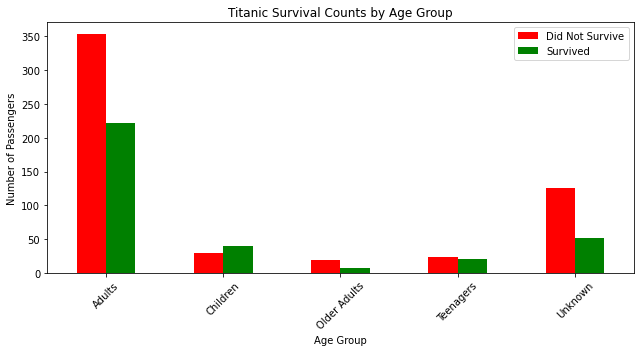

In [22]:
# Plot the conditional percentage who survived.
age_counts.plot(
    kind="bar",
    figsize=(9, 5),
    color=["red", "green"]
)

plt.title("Titanic Survival Counts by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Passengers")
plt.legend(["Did Not Survive", "Survived"])
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

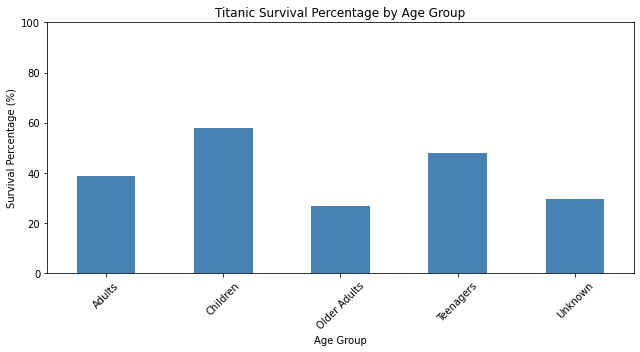

In [24]:
age_percentages[1].plot(
    kind="bar",
    figsize=(9, 5),
    color="steelblue"
)

plt.title("Titanic Survival Percentage by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Survival Percentage (%)")
plt.ylim(0, 100)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Sex

Compare `Sex` with `Survived` using your Data-step choices.


In [25]:
# Create and display the count cross-tab.
sex_counts = pd.crosstab(
    titanic_df["Sex"],
    titanic_df["Survived"]
)

sex_counts

Survived,0,1
Sex,,
female,81,233
male,468,109


In [26]:
# Calculate conditional percentages and display only the survived column.
sex_percentages = pd.crosstab(
    titanic_df["Sex"],
    titanic_df["Survived"],
    normalize="index"
) * 100

sex_percentages.round(2)

Survived,0,1
Sex,,
female,25.80,74.20
male,81.11,18.89


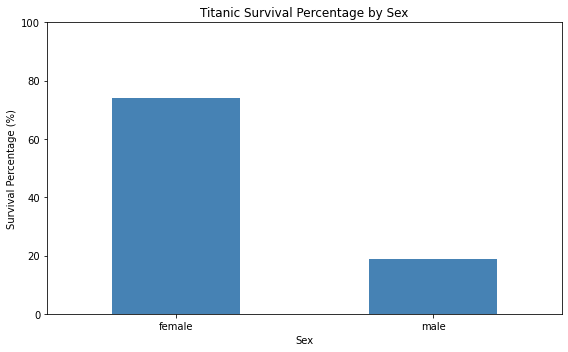

In [27]:
# Plot the conditional percentage who survived.
sex_percentages[1].plot(
    kind="bar",
    figsize=(8, 5),
    color="steelblue"
)

plt.title("Titanic Survival Percentage by Sex")
plt.xlabel("Sex")
plt.ylabel("Survival Percentage (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Passenger class

Compare `Pclass` with `Survived` using your Data-step choices.


In [28]:
# Create and display the count cross-tab.
class_counts = pd.crosstab(
    titanic_df["Pclass"],
    titanic_df["Survived"]
)

class_counts

Survived,0,1
Pclass,,
1,80,136
2,97,87
3,372,119


In [29]:
# Calculate conditional percentages and display only the survived column.
class_percentages = pd.crosstab(
    titanic_df["Pclass"],
    titanic_df["Survived"],
    normalize="index"
) * 100

class_percentages.round(2)

Survived,0,1
Pclass,,
1,37.04,62.96
2,52.72,47.28
3,75.76,24.24


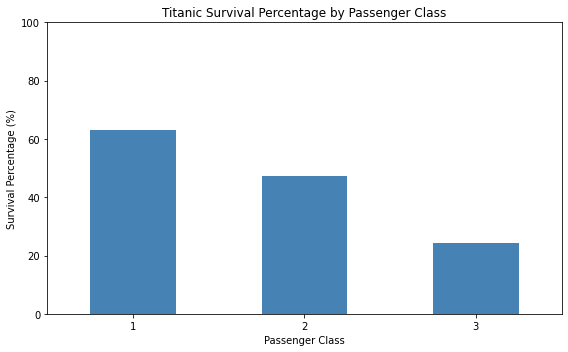

In [30]:
# Plot the conditional percentage who survived.
class_percentages[1].plot(
    kind="bar",
    figsize=(8, 5),
    color="steelblue"
)

plt.title("Titanic Survival Percentage by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Percentage (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Parents or children aboard

Compare `Parch or your derived group` with `Survived` using your Data-step choices.


In [50]:
# Create and display the count cross-tab.
parch_counts = pd.crosstab(
    titanic_df["Parch_group"],
    titanic_df["Survived"]
)

parch_counts

Survived,0,1
Parch_group,,
0,445,233
1,53,65
2 or more,51,44


In [32]:
# Calculate conditional percentages and display only the survived column.
parch_percentages = pd.crosstab(
    titanic_df["Parch"],
    titanic_df["Survived"],
    normalize="index"
) * 100

parch_percentages.round(2)

Survived,0,1
Parch,,
0,65.63,34.37
1,44.92,55.08
2,50.00,50.00
3,40.00,60.00
4,100.00,0.00
5,80.00,20.00
6,100.00,0.00


In [51]:
# Plot the conditional percentage who survived.
parch_percentages = pd.crosstab(
    titanic_df["Parch_group"],
    titanic_df["Survived"],
    normalize="index"
) * 100

parch_percentages.round(2)

Survived,0,1
Parch_group,,
0,65.63,34.37
1,44.92,55.08
2 or more,53.68,46.32


### Siblings or spouse aboard

Compare `SibSp or your derived group` with `Survived` using your Data-step choices.


In [34]:
# Create and display the count cross-tab.
sibsp_counts = pd.crosstab(
    titanic_df["SibSp"],
    titanic_df["Survived"]
)

sibsp_counts

Survived,0,1
SibSp,,
0,398,210
1,97,112
2,15,13
3,12,4
4,15,3
5,5,0
8,7,0


In [35]:
# Calculate conditional percentages and display only the survived column.
sibsp_percentages = pd.crosstab(
    titanic_df["SibSp"],
    titanic_df["Survived"],
    normalize="index"
) * 100

sibsp_percentages.round(2)

Survived,0,1
SibSp,,
0,65.46,34.54
1,46.41,53.59
2,53.57,46.43
3,75.00,25.00
4,83.33,16.67
5,100.00,0.00
8,100.00,0.00


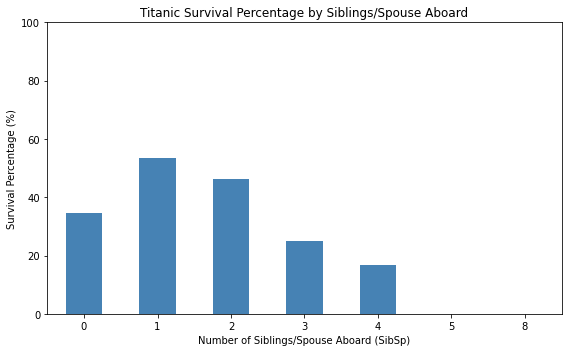

In [36]:
# Plot the conditional percentage who survived.
sibsp_percentages[1].plot(
    kind="bar",
    figsize=(8, 5),
    color="steelblue"
)

plt.title("Titanic Survival Percentage by Siblings/Spouse Aboard")
plt.xlabel("Number of Siblings/Spouse Aboard (SibSp)")
plt.ylabel("Survival Percentage (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Embarkation port

Compare `Embarked` with `Survived` using your Data-step choices.


In [37]:
# Create and display the count cross-tab.
embarked_counts = pd.crosstab(
    titanic_df["Embarked"].fillna("Unknown"),
    titanic_df["Survived"]
)

embarked_counts

Survived,0,1
Embarked,,
C,75,93
Q,47,30
S,427,217
Unknown,0,2


In [38]:
# Calculate conditional percentages and display only the survived column.
embarked_percentages = pd.crosstab(
    titanic_df["Embarked"].fillna("Unknown"),
    titanic_df["Survived"],
    normalize="index"
) * 100

embarked_percentages.round(2)

Survived,0,1
Embarked,,
C,44.64,55.36
Q,61.04,38.96
S,66.30,33.70
Unknown,0.00,100.00


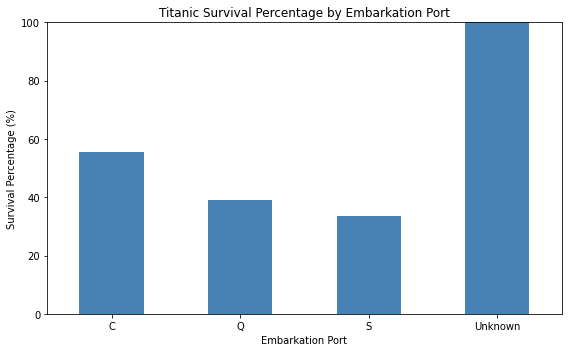

In [39]:
# Plot the conditional percentage who survived.
embarked_percentages[1].plot(
    kind="bar",
    figsize=(8, 5),
    color="steelblue"
)

plt.title("Titanic Survival Percentage by Embarkation Port")
plt.xlabel("Embarkation Port")
plt.ylabel("Survival Percentage (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [40]:
for name, feature in [
    ("Age groups", "age_group"),
    ("Sex", "Sex"),
    ("Passenger class", "Pclass"),
    ("Parents or children", "Parch"),
    ("Siblings or spouse", "SibSp"),
    ("Embarkation port", "Embarked")
]:
    print("\n", name)
    print(pd.crosstab(
        titanic_df[feature].fillna("Unknown"),
        titanic_df["Survived"],
        margins=True
    ))


 Age groups
Survived        0    1  All
age_group                  
Adults        353  222  575
Children       29   40   69
Older Adults   19    7   26
Teenagers      23   21   44
Unknown       125   52  177
All           549  342  891

 Sex
Survived    0    1  All
Sex                    
female     81  233  314
male      468  109  577
All       549  342  891

 Passenger class
Survived    0    1  All
Pclass                 
1          80  136  216
2          97   87  184
3         372  119  491
All       549  342  891

 Parents or children
Survived    0    1  All
Parch                  
0         445  233  678
1          53   65  118
2          40   40   80
3           2    3    5
4           4    0    4
5           4    1    5
6           1    0    1
All       549  342  891

 Siblings or spouse
Survived    0    1  All
SibSp                  
0         398  210  608
1          97  112  209
2          15   13   28
3          12    4   16
4          15    3   18
5           5    0    5


### Summarize the evidence

Record the highest- and lowest-survival categories for each feature. Include percentages and group sizes; mention ties or very small groups that affect interpretation.



| Feature | Highest-survival category, percentage, and group size | Lowest-survival category, percentage, and group size |
| --- | --- | --- |
| Age group | Children: 57.97% (40 of 69) | Older Adults: 26.92% (7 of 26) |
| Sex | Female: 74.20% (233 of 314) | Male: 18.89% (109 of 577) |
| Passenger class | First Class: 62.96% (136 of 216) | Third Class: 24.24% (119 of 491) |
| Parents/children aboard (Parch) | 3 aboard: 60.00% (3 of 5) | 4 or 6 aboard: 0.00% (0 of 4; 0 of 1) |
| Siblings/spouse aboard (SibSp) | 1 aboard: 53.59% (112 of 209) | 5 or 8 aboard: 0.00% (0 of 5; 0 of 7) |
| Embarkation port | Unknown: 100.00% (2 of 2); highest recorded port: Cherbourg (C), 55.36% (93 of 168) | Southampton (S): 33.70% (217 of 644) |

**Using the age comparison, interpret one joint percentage and one conditional percentage. What denominator does each use, and which figure answers the survival-likelihood question more clearly?**

Your answer:  The results show that sex and passenger class have some of the strongest relationships with survival. Female passengers had a 74.20% survival rate compared with 18.89% for males. First-class passengers had a 62.96% survival rate, while third-class passengers had only 24.24%.

Age also appears to matter, with children having the highest survival rate among the age groups at 57.97%. Family relationships and embarkation ports show differences as well, but some categories contain very few passengers. For example, the Unknown embarkation category has a 100% survival rate, but it only contains two passengers.

Because of these small sample sizes, I would place more confidence in patterns supported by larger groups. These results support my original prediction that women, children, and first-class passengers were generally more likely to survive, while adult men traveling in third class were less likely.

## Step 4: Check

Check the meaning of your combined evidence, rather than repeating the initial row count or missing-value inspection.

- Compare each age group's minimum and maximum known ages with your declared boundaries, including exact cutoffs and unknown ages.
- If you collapsed travel-companion categories, cross-tab the original counts against your group labels.
- Check that percentages use all passengers in the relevant group, not just survivors. Compare the direction of the percentages with the count tables.
- Identify sparse groups or implausible values that deserve caution.


In [41]:
# Check age-group boundaries and unknown ages.
titanic_df.groupby("age_group")["Age"].agg(["count", "min", "max"])

,count,min,max
age_group,,,
Adults,575,18.00,59.0
Children,69,0.42,12.0
Older Adults,26,60.00,80.0
Teenagers,44,13.00,17.0
Unknown,0,NaN,NaN


In [42]:
# Check travel-companion category mappings if you created grouped features.
print("Parch values:")
print(titanic_df["Parch"].value_counts().sort_index())

print("\nSibSp values:")
print(titanic_df["SibSp"].value_counts().sort_index())

print("\nTotal passengers:", len(titanic_df))

Parch values:
0    678
1    118
2     80
3      5
4      4
5      5
6      1
Name: Parch, dtype: int64

SibSp values:
0    608
1    209
2     28
3     16
4     18
5      5
8      7
Name: SibSp, dtype: int64

Total passengers: 891


**Do the age boundaries, category mappings, and denominators match your intentions? What would make you suspicious, and did you find or correct any issues? Which small groups limit interpretation?**

Your answer:  I checked the age-group boundaries to make sure passengers were placed in the correct categories without overlapping ages. The 177 passengers with missing ages remain in the Unknown category rather than being assigned an estimated age.

I also reviewed the Parch and SibSp counts. Some categories contain very few passengers, which can make their survival percentages misleading. Although I originally planned to group these values into 0, 1, and 2 or more, the current analysis uses the original counts, so I need to account for those small groups when interpreting the results.

I verified that the dataset contains 891 passengers. Conditional survival percentages use the number of passengers within each category as the denominator, while joint percentages use all 891 passengers.

These checks help ensure the calculations are accurate and that the conclusions reflect what the data actually supports.

## Step 5: Conclusion

Use the combined evidence to develop the two profiles, find matching passengers, and connect them to historical biographies.


### Build your two character profiles

Combine the evidence into a “most likely to survive” profile and a “least likely to survive” profile. Include all six elements. Cite the relevant group percentage and size for each choice. Do not multiply separate feature percentages to produce an individual survival probability: the features may be related, and separate comparisons do not establish the survival rate for their combination.



| Profile element | Most likely profile: category and evidence | Least likely profile: category and evidence |
| --- | --- | --- |
| Sex | Female: 74.20% survived (233 of 314). | Male: 18.89% survived (109 of 577). |
| Age groups | Children: 57.97% survived (40 of 69). | Older Adults: 26.92% survived (7 of 26). |
| Passenger class | First class: 62.96% survived (136 of 216). | Third class: 24.24% survived (119 of 491). |
| Parents or children aboard | 1 aboard: 55.08% survived (65 of 118). | 4 aboard: 0% survived (0 of 4). |
| Siblings or spouse aboard | 1 aboard: 53.59% survived (112 of 209). | 5 aboard: 0% survived (0 of 5). |
| Embarkation port | Cherbourg (C): 55.36% survived (93 of 168). | Southampton (S): 33.70% survived (217 of 644). |

**Write a short character description for each profile. Explain any tradeoffs where the evidence does not point to a single obvious combination.**

Your answer:  **Most Likely to Survive:** My first character would be a young female passenger traveling in first class, boarding at Cherbourg, with one family member aboard. The data shows that females had a 74.20% survival rate, first-class passengers had a 62.96% survival rate, and children had a 57.97% survival rate. These characteristics suggest a higher likelihood of survival.

**Least Likely to Survive:** My second character would be an older male passenger traveling in third class, boarding at Southampton, possibly with several family members aboard. Males had an 18.89% survival rate, third-class passengers had a 24.24% survival rate, and older adults had a 26.92% survival rate.

**Tradeoffs:** These profiles are based on survival percentages for individual characteristics, not the exact combination of all six features. Some family-size categories contain very few passengers, so I wouldn't rely heavily on those extreme percentages. The profiles represent patterns in the data rather than guaranteed outcomes.

### Find real passengers who fit

Use Boolean conditions with `.loc` to find passengers matching each profile across all six elements. Save the results as `most_likely_df` and `least_likely_df`, and display their names and the features used to match them. **Do not filter on `Survived` to build these lists**: an actual outcome is not a profile characteristic.

If a list is empty, explain which combination has no matching record, then revise and justify your profile transparently using the evidence. Keep all six elements in your revised profile, update the profile table, and rerun the filter. Do not silently drop a condition or invent a passenger. You need at least one matching person in each list.


In [46]:
# Create most_likely_df and display matching names and profile features.

most_likely_df = titanic_df.loc[
    (titanic_df["Sex"] == "female") &
    (titanic_df["age_group"] == "Adults") &
    (titanic_df["Pclass"] == 1) &
    (titanic_df["Parch"] == 1) &
    (titanic_df["SibSp"] == 1) &
    (titanic_df["Embarked"] == "C")
]

most_likely_df[
    ["PassengerId", "Name", "Sex", "Age",
     "age_group", "Pclass", "Parch", "SibSp",
     "Embarked", "Survived"]
]

,PassengerId,Name,Sex,Age,age_group,Pclass,Parch,SibSp,Embarked,Survived
319,320,"Spedden, Mrs. Frederic Oakley (Margaretta Corn...",female,40.0,Adults,1,1,1,C,1
581,582,"Thayer, Mrs. John Borland (Marian Longstreth M...",female,39.0,Adults,1,1,1,C,1
835,836,"Compton, Miss. Sara Rebecca",female,39.0,Adults,1,1,1,C,1


In [47]:
# Create least_likely_df and display matching names and profile features.

least_likely_df = titanic_df.loc[
    (titanic_df["Sex"] == "male") &
    (titanic_df["age_group"] == "Older Adults") &
    (titanic_df["Pclass"] == 3) &
    (titanic_df["Parch"] == 0) &
    (titanic_df["SibSp"] == 0) &
    (titanic_df["Embarked"] == "S")
]

least_likely_df[
    ["PassengerId", "Name", "Sex", "Age",
     "age_group", "Pclass", "Parch", "SibSp",
     "Embarked", "Survived"]
]

,PassengerId,Name,Sex,Age,age_group,Pclass,Parch,SibSp,Embarked,Survived
326,327,"Nysveen, Mr. Johan Hansen",male,61.0,Older Adults,3,0,0,S,0
851,852,"Svensson, Mr. Johan",male,74.0,Older Adults,3,0,0,S,0


**How do your filters match the six profile choices? Document any revisions needed to obtain real matches.**

Your answer:  Both filters use all six characteristics: age group, sex, passenger class, parents/children aboard (Parch), siblings/spouse aboard (SibSp), and embarkation port. I did not filter by survival outcome because the purpose was to identify passengers based on their characteristics.

My original combinations were too restrictive and returned no matching passengers, so I adjusted them while keeping all six characteristics.

For the most-likely-to-survive profile, I changed the age group from Children to Adults, which produced three matching passengers. For the least-likely-to-survive profile, I changed both Parch and SibSp to zero, which produced two matching passengers.

These adjustments were necessary to identify real people in the dataset. They also demonstrate that combining individually favorable or unfavorable characteristics does not guarantee that a passenger with every characteristic actually existed.

### Connect the records to people

Choose one person from `most_likely_df` and one from `least_likely_df`. Find each person on [Encyclopedia Titanica](https://www.encyclopedia-titanica.org/) using its passenger lists or biography search. Check identifying details to make sure you found the same person; names can have spelling variations.

For each person, select at least one interesting fact from the biography beyond the values already listed in your dataset. Describe it in your own words and link directly to the biography. Do not substitute an uncited fact or just restate survival status.


**Who did you choose from your “most likely to survive” list? Give the dataset name and PassengerId, explain how you matched the biography, describe an interesting fact, and provide the direct Encyclopedia Titanica biography URL.**

Your answer:  Most-Likely-to-Survive Profile — Margaretta Corning Spedden

Margaretta Spedden was a 39-year-old first-class passenger who boarded the Titanic at Cherbourg. She traveled with her husband and son and survived the sinking in lifeboat 3. She later wrote a story about the experience through the perspective of her son's toy bear. Her survival is consistent with the higher survival percentages observed among female and first-class passengers.

https://www.encyclopedia-titanica.org/titanic-survivor/margaretta-corning-spedden.html 

**Who did you choose from your “least likely to survive” list? Give the dataset name and PassengerId, explain how you matched the biography, describe an interesting fact, and provide the direct Encyclopedia Titanica biography URL.**

Your answer:  Least-Likely-to-Survive Profile — Johannes Hansen Nysveen

Johannes Hansen Nysveen was a 60-year-old Norwegian farmer traveling in third class. He boarded at Southampton and was heading to North Dakota. He died when the Titanic sank, and his body was never identified. His outcome is consistent with the lower survival percentages observed among male, older, and third-class passengers.

https://www.encyclopedia-titanica.org/titanic-victim/johan-hansen-nysveen.html

After choosing the people, compare their recorded survival outcomes with their profiles. A passenger can contradict a group tendency. If the biography conflicts with this dataset, report the disagreement and what the sources say rather than silently changing the data.


In [48]:
# Display the selected passengers and their recorded survival outcomes.
print("Most Likely to Survive:")
display(most_likely_df[["PassengerId", "Name", "Survived"]])

print("Least Likely to Survive:")
display(least_likely_df[["PassengerId", "Name", "Survived"]])

Most Likely to Survive:


,PassengerId,Name,Survived
319,320,"Spedden, Mrs. Frederic Oakley (Margaretta Corn...",1
581,582,"Thayer, Mrs. John Borland (Marian Longstreth M...",1
835,836,"Compton, Miss. Sara Rebecca",1


Least Likely to Survive:


,PassengerId,Name,Survived
326,327,"Nysveen, Mr. Johan Hansen",0
851,852,"Svensson, Mr. Johan",0


**Did each person's actual outcome align with the profile label? What does this show about using group patterns to describe individuals? Note any discrepancies with the biographies.**

Your answer:  Yes, the actual survival outcomes matched my predictions. All three passengers matching my most-likely-to-survive profile survived, while both passengers matching my least-likely-to-survive profile did not.

This supports the patterns identified in my analysis, particularly the differences associated with sex and passenger class. However, these groups contain only three and two passengers, so I cannot assume everyone with similar characteristics would have experienced the same outcome.

The results show how statistical patterns can help identify survival likelihood without guaranteeing an individual's outcome.

### Final recommendation to the director


**Recommend the two characters using numerical evidence and their biographical facts. How do your completed profiles compare with your initial predictions? Explain any tradeoffs or revisions.**

Your answer:  I recommend Margaretta Corning Spedden for the most-likely-to-survive character. She was a 39-year-old first-class female passenger who boarded at Cherbourg and survived in lifeboat 3. The data supports this choice because females had a 74.20% survival rate, first-class passengers had a 62.96% survival rate, and passengers boarding at Cherbourg had a 55.36% survival rate.

For the least-likely-to-survive character, I recommend Johan Hansen Nysveen, a 60-year-old third-class male passenger who boarded at Southampton and did not survive. Male passengers had an 18.89% survival rate, third-class passengers had a 24.24% survival rate, and older adults had a 26.92% survival rate.

My findings generally support my original predictions about sex and passenger class. However, I originally expected children to be the strongest high-survival candidates. I revised that profile to an adult because no passenger matched all six original characteristics. I also revised the family-companion counts for the low-survival profile to identify actual passengers.

These choices represent real individuals whose experiences align with the overall statistical patterns, although those patterns cannot predict anyone's outcome with certainty.

## Step 6: Limitation


**What should the director avoid concluding? Discuss why separate feature comparisons do not establish an individual survival probability or causation, and address relevant limitations such as small groups, missing ages, category choices, or uncertain historical records.**

Your answer:  The director should avoid assuming that a passenger's characteristics guarantee survival or death. The percentages show patterns among groups, but they don't establish an exact survival probability for an individual. They also don't prove that any one characteristic directly caused someone to survive.

For example, women had a much higher survival rate than men, but that doesn't mean every woman survived. Passenger class, age, and family relationships may also overlap and influence the patterns we observe.

There are limitations in the dataset, including 177 passengers with missing ages, very small groups in some family categories, and the age boundaries I selected. Different groupings might produce different results.

Overall, the data helps identify trends and develop realistic character profiles, but the director should understand that these are statistical associations, not guaranteed outcomes.

## AI-use reflection


**Did you use AI? If so, describe one suggestion you checked and accepted, modified, or rejected. If not, state that you did not use it.**

Your answer:  I used AI as an additional learning resource to help explore concepts, clarify questions, and better understand the methods used in this lab. It provided another perspective when working through the analysis and evaluating different approaches.

I found it useful for reinforcing what I've learned and developing a better understanding of how to interpret and apply the data. I reviewed the results and used my own judgment throughout the process.

## Submission checklist

- Complete one six-step workflow with an initial prediction and evidence for all six profile elements.
- Justify age boundaries and missing-age handling; use passenger class, not fare.
- Include a labeled visualization for every profile element and the age count-versus-percentage comparison.
- Support both complete profiles with group percentages and sizes.
- Display both matching-passenger lists and select one real person from each.
- Include an interesting fact and direct Encyclopedia Titanica biography link for each selected person.
- Complete the combined conclusion, limitation, and AI-use reflection.
- Restart the kernel and run all cells in order; check that claims match the output.
